In [1]:
# ============================================================
# CAPSTONE PROJECT
# Random Forest Classification of AI Dependency
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Optional: Display all columns
pd.set_option('display.max_columns', None)

In [2]:
import pandas
import numpy
import sklearn
import matplotlib
import seaborn

print("All packages imported successfully!")

All packages imported successfully!


In [3]:
!pip install openpyxl

In [4]:
import openpyxl

print("Openpyxl installed successfully!")

Openpyxl installed successfully!


In [5]:
# ============================================================
# Load the datasets
# ============================================================

# Load the metadata dataset (CSV file)
metadata = pd.read_csv(
    r"C:\Users\Admin\Downloads\CoAuthor - Metadata & Survey - Metadata (creative).csv"
)

# Load the survey dataset (Excel file - Creative Writing sheet)
survey = pd.read_excel(
    r"C:\Users\Admin\Downloads\CoAuthor - Metadata & Survey.xlsx",
    sheet_name="Survey (creative)"
)

In [6]:
import sys

print(sys.executable)

C:\Users\Admin\.conda\envs\assignment_env\python.exe


In [7]:
import pandas as pd
import sklearn
import seaborn as sns

print("Everything imported successfully!")

Everything imported successfully!


In [8]:
# ============================================================
# Display the first five rows of each dataset
# ============================================================

print("Metadata Dataset")
display(metadata.head())

print("\nSurvey Dataset")
display(survey.head())

Metadata Dataset


,timestamp,worker_id,session_id,prompt_code,temperature,frequency_penalty,num_query,num_selected,perc_selected,num_cursor,time,num_event,written_by_human
0,8/15/2021 17:22:29,A2QX3YJXAAHHVV,36bc101319da4b3590b96bce76f7c02c,shapeshifter,0.75,1,36,25,69,23,9.98,1021,30
1,8/15/2021 17:23:35,A394JO4NEPCY3M,9aca14b9d4bc4e4b9b240782bd72c6db,shapeshifter,0.30,0,5,5,100,0,9.89,2490,86
2,8/15/2021 17:24:45,A2QKAA5YS0P4CI,499f9577962c4a2c98aee3f5b6098a71,shapeshifter,0.30,0,10,9,90,433,11.31,2271,66
3,8/15/2021 17:30:11,AZLZA0Q87TJZO,7267ada18a784f5089b55427212251b3,shapeshifter,0.30,0,13,8,62,32,11.46,2546,79
4,8/15/2021 17:30:49,A2YTQDLACTLIBA,1a14bae2ca9f422ea8779752233a203a,shapeshifter,0.30,0,9,4,44,11,15.12,2470,91



Survey Dataset


,Timestamp,Please enter your worker ID,Please enter verification code from this writing session (session_id),Is English your first language?,"During this writing session, the suggestions you received were grammatically correct, and contributed to the fluency of the story.","During this writing session, the suggestions helped me come up with new ideas.","During this writing session, I felt like that I would have written a *better* story if I wrote the story alone.","During this writing session, the system was competent (having expert knowledge and ability to perform a task successfully) in writing.","During this writing session, the system was capable of writing creative stories.","During this writing session, the system understood what I was trying to write.",Which aspects of the suggestions (that you received during this writing session) can be improved? Any specific examples?,It was easy to write with the system.,I am satisfied with the story I wrote.,I am confident in my ability to write a story with the help of the system.,I feel like the story is mine.,____% of the story is written by me (and the rest is written by taking the suggestions). [between 0-100%],"If the system is available for free, I would reuse the system.",Any feedback/comment? (optional)
0,2021-08-25 20:21:59.811,A1198W1SPF1R4,8911f32aab914a1f903bb76300b13949,No,5,5,4,5,5,4,The suggestions were repetitive.,4,5,5,6,65,5,NaN
1,2021-08-27 20:25:48.579,A1198W1SPF1R4,5d9be2dad6584ff4b2ab1c6f701f64cb,No,6,5,3,5,5,6,The suggestions were not creative enough.,5,5,5,6,80,6,NaN
2,2021-08-27 21:01:55.545,A1198W1SPF1R4,a068c6552ba143c8ba4f378e49c3b640,No,6,5,2,5,5,4,The suggestions were not creative enough.,5,5,5,7,85,6,NaN
3,2021-08-29 01:33:29.867,A1198W1SPF1R4,893f5fa336ac4092b1d4efe6c91ef24f,No,6,6,2,5,5,6,Not enough suggestions were offered.,5,6,6,7,70,7,NaN
4,2021-08-29 16:54:14.255,A1198W1SPF1R4,b22279ff63804fa6bec5c108879812dd,No,6,5,3,5,4,5,"The suggestions I received were just average, ...",5,6,5,7,80,7,NaN


In [9]:
# ============================================================
# Check the dimensions of each dataset
# ============================================================

print("Metadata Dataset Shape:", metadata.shape)
print("Survey Dataset Shape:", survey.shape)

Metadata Dataset Shape: (830, 13)
Survey Dataset Shape: (833, 18)


In [10]:
# ============================================================
# Display all column names
# ============================================================

print("Metadata Columns")
print(metadata.columns.tolist())

print("\nSurvey Columns")
print(survey.columns.tolist())

Metadata Columns
['timestamp', 'worker_id', 'session_id', 'prompt_code', 'temperature', 'frequency_penalty', 'num_query', 'num_selected', 'perc_selected', 'num_cursor', 'time', 'num_event', 'written_by_human']

Survey Columns
['Timestamp', 'Please enter your worker ID', 'Please enter verification code from this writing session (session_id)', 'Is English your first language?', 'During this writing session, the suggestions you received were grammatically correct, and contributed to the fluency of the story.', 'During this writing session, the suggestions helped me come up with new ideas.', 'During this writing session, I felt like that I would have written a *better* story if I wrote the story alone.', 'During this writing session, the system was competent (having expert knowledge and ability to perform a task successfully) in writing.', 'During this writing session, the system was capable of writing creative stories.', 'During this writing session, the system understood what I was tryin

In [11]:
# ============================================================
# Check the structure of the datasets
# ============================================================

print("Metadata Information")
metadata.info()

print("\nSurvey Information")
survey.info()

Metadata Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830 entries, 0 to 829
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          830 non-null    object 
 1   worker_id          830 non-null    object 
 2   session_id         830 non-null    object 
 3   prompt_code        830 non-null    object 
 4   temperature        830 non-null    float64
 5   frequency_penalty  830 non-null    int64  
 6   num_query          830 non-null    int64  
 7   num_selected       830 non-null    int64  
 8   perc_selected      830 non-null    int64  
 9   num_cursor         830 non-null    int64  
 10  time               830 non-null    float64
 11  num_event          830 non-null    int64  
 12  written_by_human   830 non-null    int64  
dtypes: float64(2), int64(7), object(4)
memory usage: 84.4+ KB

Survey Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 833 entries, 0 to 832

In [12]:
# ============================================================
# Summary statistics for numerical variables
# ============================================================

metadata.describe()

,temperature,frequency_penalty,num_query,num_selected,perc_selected,num_cursor,time,num_event,written_by_human
count,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000
mean,0.520663,0.490361,12.831325,9.821687,75.698795,31.849398,11.621892,1959.539759,73.426506
std,0.225094,0.500209,8.757033,7.267557,20.225469,54.816793,2.676147,734.389001,16.260731
min,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,5.320000,456.000000,7.000000
25%,0.300000,0.000000,7.000000,5.000000,64.000000,6.000000,10.040000,1431.250000,65.000000
50%,0.300000,0.000000,11.000000,8.000000,79.000000,17.000000,10.845000,1863.000000,77.000000
75%,0.750000,1.000000,16.000000,13.000000,91.000000,39.000000,12.170000,2379.500000,85.000000
max,0.750000,1.000000,53.000000,47.000000,125.000000,622.000000,33.330000,6622.000000,100.000000


In [13]:
survey.describe()

,Timestamp,"During this writing session, the suggestions you received were grammatically correct, and contributed to the fluency of the story.","During this writing session, the suggestions helped me come up with new ideas.","During this writing session, I felt like that I would have written a *better* story if I wrote the story alone.","During this writing session, the system was competent (having expert knowledge and ability to perform a task successfully) in writing.","During this writing session, the system was capable of writing creative stories.","During this writing session, the system understood what I was trying to write.",It was easy to write with the system.,I am satisfied with the story I wrote.,I am confident in my ability to write a story with the help of the system.,I feel like the story is mine.,"If the system is available for free, I would reuse the system."
count,833,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000
mean,2021-08-24 16:41:07.761782528,5.997599,5.480192,2.990396,5.647059,5.511405,5.533013,5.839136,5.753902,6.045618,5.877551,5.834334
min,2021-08-15 17:22:29.239000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2021-08-18 08:47:22.694000128,5.000000,5.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,6.000000,5.000000,5.000000
50%,2021-08-24 18:25:56.431000064,6.000000,6.000000,3.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,7.000000
75%,2021-08-29 19:25:10.852999936,7.000000,7.000000,4.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
max,2021-09-05 16:36:54.252000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
std,NaN,1.084193,1.706155,1.875937,1.456185,1.613548,1.515680,1.389540,1.424608,1.272049,1.229403,1.636108


In [14]:
# ============================================================
# Check for missing values
# ============================================================

print("Missing Values in Metadata")
print(metadata.isnull().sum())

print("\nMissing Values in Survey")
print(survey.isnull().sum())

Missing Values in Metadata
timestamp            0
worker_id            0
session_id           0
prompt_code          0
temperature          0
frequency_penalty    0
num_query            0
num_selected         0
perc_selected        0
num_cursor           0
time                 0
num_event            0
written_by_human     0
dtype: int64

Missing Values in Survey
Timestamp                                                                                                                                   0
Please enter your worker ID                                                                                                                 0
Please enter verification code from this writing session (session_id)                                                                       0
Is English your first language?                                                                                                             0
During this writing session, the suggestions you received were gram

In [15]:
# ============================================================
# Check unique participants
# ============================================================

print("Unique Worker IDs:", metadata["worker_id"].nunique())
print("Unique Session IDs:", metadata["session_id"].nunique())

Unique Worker IDs: 57
Unique Session IDs: 830


In [16]:
print("Unique Worker IDs:",
      survey["Please enter your worker ID"].nunique())

print("Unique Session IDs:",
      survey["Please enter verification code from this writing session (session_id)"].nunique())

Unique Worker IDs: 58
Unique Session IDs: 832


In [17]:
# ============================================================
# Check for duplicate rows
# ============================================================

print("Duplicate rows in Metadata:", metadata.duplicated().sum())

print("Duplicate rows in Survey:", survey.duplicated().sum())

Duplicate rows in Metadata: 0
Duplicate rows in Survey: 0


In [18]:
# ============================================================
# Rename survey columns
# ============================================================

survey = survey.rename(columns={

    "Please enter your worker ID":
        "worker_id",

    "Please enter verification code from this writing session (session_id)":
        "session_id",

    "During this writing session, the suggestions you received were grammatically correct, and contributed to the fluency of the story.":
        "fluency",

    "During this writing session, the suggestions helped me come up with new ideas.":
        "new_ideas",

    "During this writing session, I felt like that I would have written a *better* story if I wrote the story alone.":
        "better_alone",

    "During this writing session, the system was competent (having expert knowledge and ability to perform a task successfully) in writing.":
        "system_competence",

    "During this writing session, the system was capable of writing creative stories.":
        "system_capability",

    "During this writing session, the system understood what I was trying to write.":
        "system_understood",

    "It was easy to write with the system.":
        "easy_to_use",

    "I am satisfied with the story I wrote.":
        "satisfaction",

    "I am confident in my ability to write a story with the help of the system.":
        "confidence",

    "I feel like the story is mine. ":
        "story_is_mine",

    "____% of the story is written by me (and the rest is written by taking the suggestions). [between 0-100%]":
        "human_contribution"

})

In [19]:
# ============================================================
# Remove unnecessary columns
# ============================================================

survey = survey.drop(columns=[

    "Timestamp",

    "Is English your first language?",

    "Which aspects of the suggestions (that you received during this writing session) can be improved? Any specific examples?",

    "Any feedback/comment? (optional)",

    "If the system is available for free, I would reuse the system."

])

In [20]:
# ============================================================
# Convert human contribution to numeric
# ============================================================

survey["human_contribution"] = pd.to_numeric(
    survey["human_contribution"],
    errors="coerce"
)

In [21]:
# ============================================================
# Identify duplicate session IDs in the survey dataset
# ============================================================

duplicate_sessions = survey[
    survey.duplicated(subset="session_id", keep=False)
]

duplicate_sessions

,worker_id,session_id,fluency,new_ideas,better_alone,system_competence,system_capability,system_understood,easy_to_use,satisfaction,confidence,story_is_mine,human_contribution
345,A2QX3YJXAAHHVV,88daaed513824fbd9c77746eec7862d9,7,6,4,6,6,7,7,7,7,3,30.0
346,A2QX3YJXAAHHVV,88daaed513824fbd9c77746eec7862d9,7,7,4,7,7,7,7,7,7,6,30.0


In [22]:
print(survey.columns.tolist())

['worker_id', 'session_id', 'fluency', 'new_ideas', 'better_alone', 'system_competence', 'system_capability', 'system_understood', 'easy_to_use', 'satisfaction', 'confidence', 'story_is_mine', 'human_contribution']


In [23]:
survey.duplicated(subset="session_id").sum()

1

In [24]:
survey[survey.duplicated(subset="session_id", keep=False)]

,worker_id,session_id,fluency,new_ideas,better_alone,system_competence,system_capability,system_understood,easy_to_use,satisfaction,confidence,story_is_mine,human_contribution
345,A2QX3YJXAAHHVV,88daaed513824fbd9c77746eec7862d9,7,6,4,6,6,7,7,7,7,3,30.0
346,A2QX3YJXAAHHVV,88daaed513824fbd9c77746eec7862d9,7,7,4,7,7,7,7,7,7,6,30.0


In [25]:
metadata[metadata["session_id"] == "88daaed513824fbd9c77746eec7862d9"]

,timestamp,worker_id,session_id,prompt_code,temperature,frequency_penalty,num_query,num_selected,perc_selected,num_cursor,time,num_event,written_by_human
228,8/18/2021 7:52:40,A2QX3YJXAAHHVV,88daaed513824fbd9c77746eec7862d9,isolation,0.3,0,13,13,100,13,10.25,456,16


In [26]:
# ============================================================
# Remove duplicate survey responses
# ============================================================

survey = survey.drop_duplicates(
    subset="session_id",
    keep="first"
)

In [27]:
print("Survey Shape:", survey.shape)
print("Duplicate Session IDs:", survey.duplicated(subset="session_id").sum())

Survey Shape: (832, 13)
Duplicate Session IDs: 0


In [28]:
# ============================================================
# Compare session IDs between metadata and survey datasets
# ============================================================

metadata_sessions = set(metadata["session_id"])
survey_sessions = set(survey["session_id"])

missing_in_metadata = survey_sessions - metadata_sessions
missing_in_survey = metadata_sessions - survey_sessions

print("Survey sessions not found in metadata:")
print(missing_in_metadata)

print("\nMetadata sessions not found in survey:")
print(missing_in_survey)

Survey sessions not found in metadata:
{'047a25c3382c42999ceb1c78f6ebd524 ', '3461ee41df7f4f5fa584f5ae04b3ba6f ', '7f9c5917c21f49ffb83d155fcc268ce9 ', '200b5a62bded44f6ba8320c117bee58a ', '6861c7f0f19645ffb563275d11fad363 ', 'b153dcf4dae74acb8ebc70ff937ecccf ', '495448baeef94ef2bff5fdba66f09b92 ', 'd8a8e6352996418a9319bbdc990bc23c ', '02a0a1349a8045bd969dfc3948ec4796 ', '35399d7a3a994ff2a0425b156a33b2d7 ', 'a609db6270b14e40a3de824554977750 ', 'ecdf98683b6641e3b99127df3ee66854 ', '9805d172a4e64a0f9c1fd87e2c2f093a ', 'e139a4f9ea0c4ea3b7b3481eea070f29 ', 'f1d6f13474954193babf52cc2eab9353 ', ' a2b882ca8a14420a8749dfedfecdfa36', 'a96faa69af9e4ad4a252760ed12177aa ', '8aaeed79e40d463dbc24a84ec0784b64 ', '9350869f0d24492c920c83e0a9507648 ', '8fe4b8a137ba4a7abe80e5c005f7490f ', 'f8e0496b35c64e35b500e2034493eb8e ', '935513674eb5493c99261d5e137fc1bd ', '1ec9f48e9a5c40adb8e6062f233df76f ', '947065accb8b402c98fb2aa62a497842 ', ' cca8806768104c18b972db618f17a37f', ' 0ff12af0651e4b0eaf88e22e82058137'

In [29]:
# ============================================================
# Remove leading and trailing spaces from IDs
# ============================================================

survey["session_id"] = survey["session_id"].str.strip()
metadata["session_id"] = metadata["session_id"].str.strip()

In [30]:
# Remove invalid session IDs and create a fresh copy
survey = survey[survey["session_id"] != "SERVER ERROR"].copy()

In [31]:
# ============================================================
# Remove leading and trailing whitespace
# ============================================================

survey["session_id"] = survey["session_id"].str.strip()
survey["worker_id"] = survey["worker_id"].str.strip()

metadata["session_id"] = metadata["session_id"].str.strip()
metadata["worker_id"] = metadata["worker_id"].str.strip()

In [32]:
metadata_sessions = set(metadata["session_id"])
survey_sessions = set(survey["session_id"])

missing_in_metadata = survey_sessions - metadata_sessions
missing_in_survey = metadata_sessions - survey_sessions

print("Survey sessions not found in metadata:", len(missing_in_metadata))
print("Metadata sessions not found in survey:", len(missing_in_survey))

Survey sessions not found in metadata: 2
Metadata sessions not found in survey: 1


In [33]:
# ============================================================
# Merge Metadata and Survey datasets
# ============================================================

merged_data = pd.merge(
    metadata,
    survey,
    on=["worker_id", "session_id"],
    how="inner"
)

print("Merged Dataset Shape:", merged_data.shape)

Merged Dataset Shape: (829, 24)


In [34]:
# ============================================================
# Verify the merged dataset
# ============================================================

print("Rows:", merged_data.shape[0])
print("Columns:", merged_data.shape[1])

print("\nMissing Values")
print(merged_data.isnull().sum())

Rows: 829
Columns: 24

Missing Values
timestamp             0
worker_id             0
session_id            0
prompt_code           0
temperature           0
frequency_penalty     0
num_query             0
num_selected          0
perc_selected         0
num_cursor            0
time                  0
num_event             0
written_by_human      0
fluency               0
new_ideas             0
better_alone          0
system_competence     0
system_capability     0
system_understood     0
easy_to_use           0
satisfaction          0
confidence            0
story_is_mine         0
human_contribution    1
dtype: int64


In [35]:
merged_data = merged_data.dropna(subset=["human_contribution"])

In [36]:
# ============================================================
# Create a working copy
# ============================================================

df = merged_data.copy()

In [37]:
# ============================================================
# Variables used in the Dependency Model
# ============================================================

dependency_variables = [

    # AI Assistance Seeking
    "num_query",

    # AI Acceptance
    "perc_selected",
    "num_selected",

    # Human Agency
    "written_by_human",
    "human_contribution",

    # Active Cognitive Engagement
    "num_cursor",
    "num_event",
    "time",

    # Psychological Trust & Utility
    "system_competence",
    "system_capability",
    "system_understood",
    "fluency",
    "new_ideas",

    # Psychological Ownership
    "story_is_mine",
    "satisfaction",
    "confidence"

]

print(df[dependency_variables].head())

   num_query  perc_selected  num_selected  written_by_human  \
0         36             69            25                30   
1          5            100             5                86   
2         10             90             9                66   
3         13             62             8                79   
4          9             44             4                91   

   human_contribution  num_cursor  num_event   time  system_competence  \
0                50.0          23       1021   9.98                  7   
1                80.0           0       2490   9.89                  6   
2                90.0         433       2271  11.31                  7   
3                75.0          32       2546  11.46                  7   
4                85.0          11       2470  15.12                  4   

   system_capability  system_understood  fluency  new_ideas  story_is_mine  \
0                  7                  7        7          7              7   
1                  6

In [38]:
from sklearn.preprocessing import MinMaxScaler

# ============================================================
# Normalize variables
# ============================================================

scaler = MinMaxScaler()

df_scaled = df.copy()

df_scaled[dependency_variables] = scaler.fit_transform(
    df[dependency_variables]
)

In [39]:
df_scaled[dependency_variables].describe()

,num_query,perc_selected,num_selected,written_by_human,human_contribution,num_cursor,num_event,time,system_competence,system_capability,system_understood,fluency,new_ideas,story_is_mine,satisfaction,confidence
count,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000,828.000000
mean,0.242230,0.605507,0.209066,0.714210,0.720100,0.051195,0.244061,0.225110,0.774758,0.751208,0.756039,0.833333,0.746981,0.813003,0.791667,0.840580
std,0.165406,0.161799,0.154790,0.175049,0.158624,0.088205,0.119164,0.095622,0.242358,0.269164,0.251551,0.180316,0.284321,0.205451,0.237918,0.212345
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.132075,0.512000,0.106383,0.623656,0.646821,0.009646,0.158247,0.168511,0.666667,0.666667,0.666667,0.666667,0.666667,0.666667,0.666667,0.833333
50%,0.207547,0.632000,0.170213,0.752688,0.747730,0.027331,0.228268,0.197608,0.833333,0.833333,0.833333,0.833333,0.833333,0.833333,0.833333,0.833333
75%,0.301887,0.728000,0.276596,0.838710,0.848638,0.062701,0.312196,0.244645,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [40]:
# ============================================================
# AI Assistance Seeking
# ============================================================

df_scaled["AI_Assistance_Seeking"] = df_scaled["num_query"]

In [41]:
# ============================================================
# AI Acceptance
# ============================================================

df_scaled["AI_Acceptance"] = (
    df_scaled[
        ["perc_selected", "num_selected"]
    ].mean(axis=1)
)

In [42]:
# ============================================================
# Human Agency
# ============================================================

human_agency = df_scaled[
    ["written_by_human", "human_contribution"]
].mean(axis=1)

df_scaled["Human_Agency"] = 1 - human_agency

In [43]:
# ============================================================
# Active Cognitive Engagement
# ============================================================

engagement = df_scaled[
    ["num_cursor", "num_event", "time"]
].mean(axis=1)

df_scaled["Active_Cognitive_Engagement"] = 1 - engagement

In [44]:
# ============================================================
# Psychological Trust & Utility
# ============================================================

df_scaled["Psychological_Trust_Utility"] = (
    df_scaled[
        [
            "system_competence",
            "system_capability",
            "system_understood",
            "fluency",
            "new_ideas"
        ]
    ].mean(axis=1)
)

In [45]:
# ============================================================
# Psychological Ownership
# ============================================================

ownership = df_scaled[
    [
        "story_is_mine",
        "satisfaction",
        "confidence"
    ]
].mean(axis=1)

df_scaled["Psychological_Ownership"] = 1 - ownership

In [46]:
constructs = [
    "AI_Assistance_Seeking",
    "AI_Acceptance",
    "Human_Agency",
    "Active_Cognitive_Engagement",
    "Psychological_Trust_Utility",
    "Psychological_Ownership"
]

df_scaled[constructs].describe()

,AI_Assistance_Seeking,AI_Acceptance,Human_Agency,Active_Cognitive_Engagement,Psychological_Trust_Utility,Psychological_Ownership
count,828.000000,828.000000,828.000000,828.000000,828.000000,8.280000e+02
mean,0.242230,0.407286,0.282845,0.826545,0.772464,1.849168e-01
std,0.165406,0.127912,0.148816,0.081693,0.223751,1.706240e-01
min,0.000000,0.000000,0.000000,0.020469,0.000000,1.110223e-16
25%,0.132075,0.331894,0.176177,0.804548,0.666667,5.555556e-02
50%,0.207547,0.421277,0.267203,0.845760,0.833333,1.666667e-01
75%,0.301887,0.485021,0.361763,0.875033,0.966667,2.777778e-01
max,1.000000,0.856000,0.954087,0.985932,1.000000,1.000000e+00


In [47]:
# ============================================================
# Correlation between construct scores
# ============================================================

constructs = [
    "AI_Assistance_Seeking",
    "AI_Acceptance",
    "Human_Agency",
    "Active_Cognitive_Engagement",
    "Psychological_Trust_Utility",
    "Psychological_Ownership"
]

df_scaled[constructs].corr()

,AI_Assistance_Seeking,AI_Acceptance,Human_Agency,Active_Cognitive_Engagement,Psychological_Trust_Utility,Psychological_Ownership
AI_Assistance_Seeking,1.000000,0.610826,0.685130,0.084466,-0.038009,0.209063
AI_Acceptance,0.610826,1.000000,0.626703,0.025144,0.153601,0.028020
Human_Agency,0.685130,0.626703,1.000000,0.254593,0.194281,0.109702
Active_Cognitive_Engagement,0.084466,0.025144,0.254593,1.000000,-0.046308,0.126578
Psychological_Trust_Utility,-0.038009,0.153601,0.194281,-0.046308,1.000000,-0.624329
Psychological_Ownership,0.209063,0.028020,0.109702,0.126578,-0.624329,1.000000


In [48]:
# ============================================================
# Compute the Composite Dependency Index
# ============================================================

constructs = [
    "AI_Assistance_Seeking",
    "AI_Acceptance",
    "Human_Agency",
    "Active_Cognitive_Engagement",
    "Psychological_Trust_Utility",
    "Psychological_Ownership"
]

df_scaled["Dependency_Index"] = df_scaled[constructs].mean(axis=1)

In [49]:
df_scaled["Dependency_Index"].describe()

count    828.000000
mean       0.452714
std        0.080937
min        0.199308
25%        0.399601
50%        0.441872
75%        0.495296
max        0.800811
Name: Dependency_Index, dtype: float64

In [50]:
# ============================================================
# Create AI Dependency Levels
# ============================================================

df_scaled["Dependency_Level"] = pd.qcut(
    df_scaled["Dependency_Index"],
    q=3,
    labels=["Low", "Moderate", "High"]
)

In [51]:
# ============================================================
# Check class balance
# ============================================================

print(df_scaled["Dependency_Level"].value_counts())

print("\n")

print(df_scaled["Dependency_Level"].value_counts(normalize=True) * 100)

Dependency_Level
Low         276
Moderate    276
High        276
Name: count, dtype: int64


Dependency_Level
Low         33.333333
Moderate    33.333333
High        33.333333
Name: proportion, dtype: float64


In [52]:
# ============================================================
# Feature Matrix (X)
# ============================================================

X = df_scaled[
    [
        "AI_Assistance_Seeking",
        "AI_Acceptance",
        "Human_Agency",
        "Active_Cognitive_Engagement",
        "Psychological_Trust_Utility",
        "Psychological_Ownership"
    ]
]

# Target Variable
y = df_scaled["Dependency_Level"]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (828, 6)
Target Shape: (828,)


In [53]:
from sklearn.model_selection import train_test_split

# ============================================================
# Split into Training and Testing Sets
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (662, 6)
Testing Set: (166, 6)


In [54]:
from sklearn.ensemble import RandomForestClassifier

In [55]:
# ============================================================
# Random Forest Classifier
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

In [56]:
# ============================================================
# Train the Random Forest
# ============================================================

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [57]:
# ============================================================
# Predict on Test Data
# ============================================================

y_pred = rf_model.predict(X_test)

In [58]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [59]:
# ============================================================
# Model Accuracy
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")

Model Accuracy: 0.8313


In [60]:
# ============================================================
# Classification Report
# ============================================================

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.92      0.85      0.89        55
         Low       0.84      0.87      0.86        55
    Moderate       0.74      0.77      0.75        56

    accuracy                           0.83       166
   macro avg       0.84      0.83      0.83       166
weighted avg       0.83      0.83      0.83       166



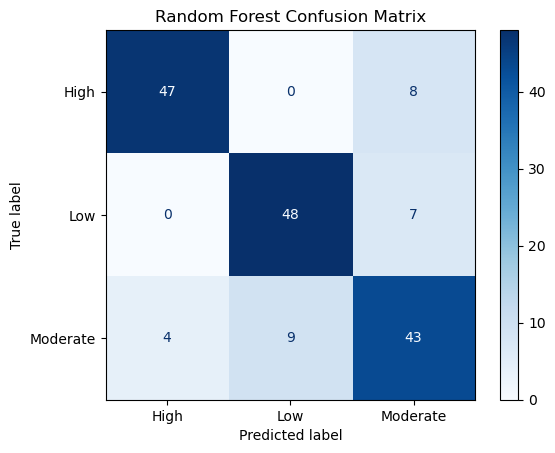

In [61]:
# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [62]:
# ============================================================
# Feature Importance
# ============================================================

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({

    "Construct": X.columns,

    "Importance": importance

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                     Construct  Importance
2                 Human_Agency    0.369538
0        AI_Assistance_Seeking    0.175187
1                AI_Acceptance    0.170692
3  Active_Cognitive_Engagement    0.120573
4  Psychological_Trust_Utility    0.095975
5      Psychological_Ownership    0.068034


In [63]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

In [64]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)

print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 0.8072289156626506
              precision    recall  f1-score   support

        High       0.83      0.80      0.81        55
         Low       0.85      0.91      0.88        55
    Moderate       0.74      0.71      0.73        56

    accuracy                           0.81       166
   macro avg       0.81      0.81      0.81       166
weighted avg       0.81      0.81      0.81       166



In [65]:
cm_dt = confusion_matrix(y_test, dt_predictions)

print(cm_dt)

[[44  0 11]
 [ 2 50  3]
 [ 7  9 40]]


In [66]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(cv_scores)

print("Mean Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

[0.78915663 0.8313253  0.89156627 0.82424242 0.88484848]
Mean Accuracy: 0.8442278203723987
Standard Deviation: 0.038703214804851116


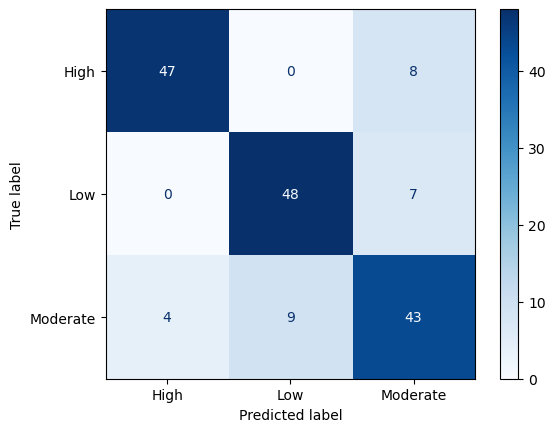

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test,
    cmap="Blues"
)

In [68]:

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

In [75]:
print(type(rf_model))
print(rf_model)

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)


In [76]:
print(rf_model.feature_importances_)

[0.17518711 0.17069241 0.36953816 0.12057317 0.09597538 0.06803377]


In [77]:
print(X.columns)

Index(['AI_Assistance_Seeking', 'AI_Acceptance', 'Human_Agency',
       'Active_Cognitive_Engagement', 'Psychological_Trust_Utility',
       'Psychological_Ownership'],
      dtype='object')


In [79]:
# ==========================================================
# MIND VS. MACHINE
# Behavioural Analytics Dashboard
# ==========================================================

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ----------------------------------------------------------
# Figure
# ----------------------------------------------------------

fig = plt.figure(figsize=(18,10), facecolor="white")

gs = gridspec.GridSpec(
    3,
    4,
    height_ratios=[1,3,2],
    hspace=0.45,
    wspace=0.35
)

fig.suptitle(
    "Mind vs. Machine\nBehavioural Analytics Dashboard",
    fontsize=24,
    fontweight='bold',
    color="#12355B"
)

Text(0.5, 0.98, 'Mind vs. Machine\nBehavioural Analytics Dashboard')

<Figure size 1800x1000 with 0 Axes>

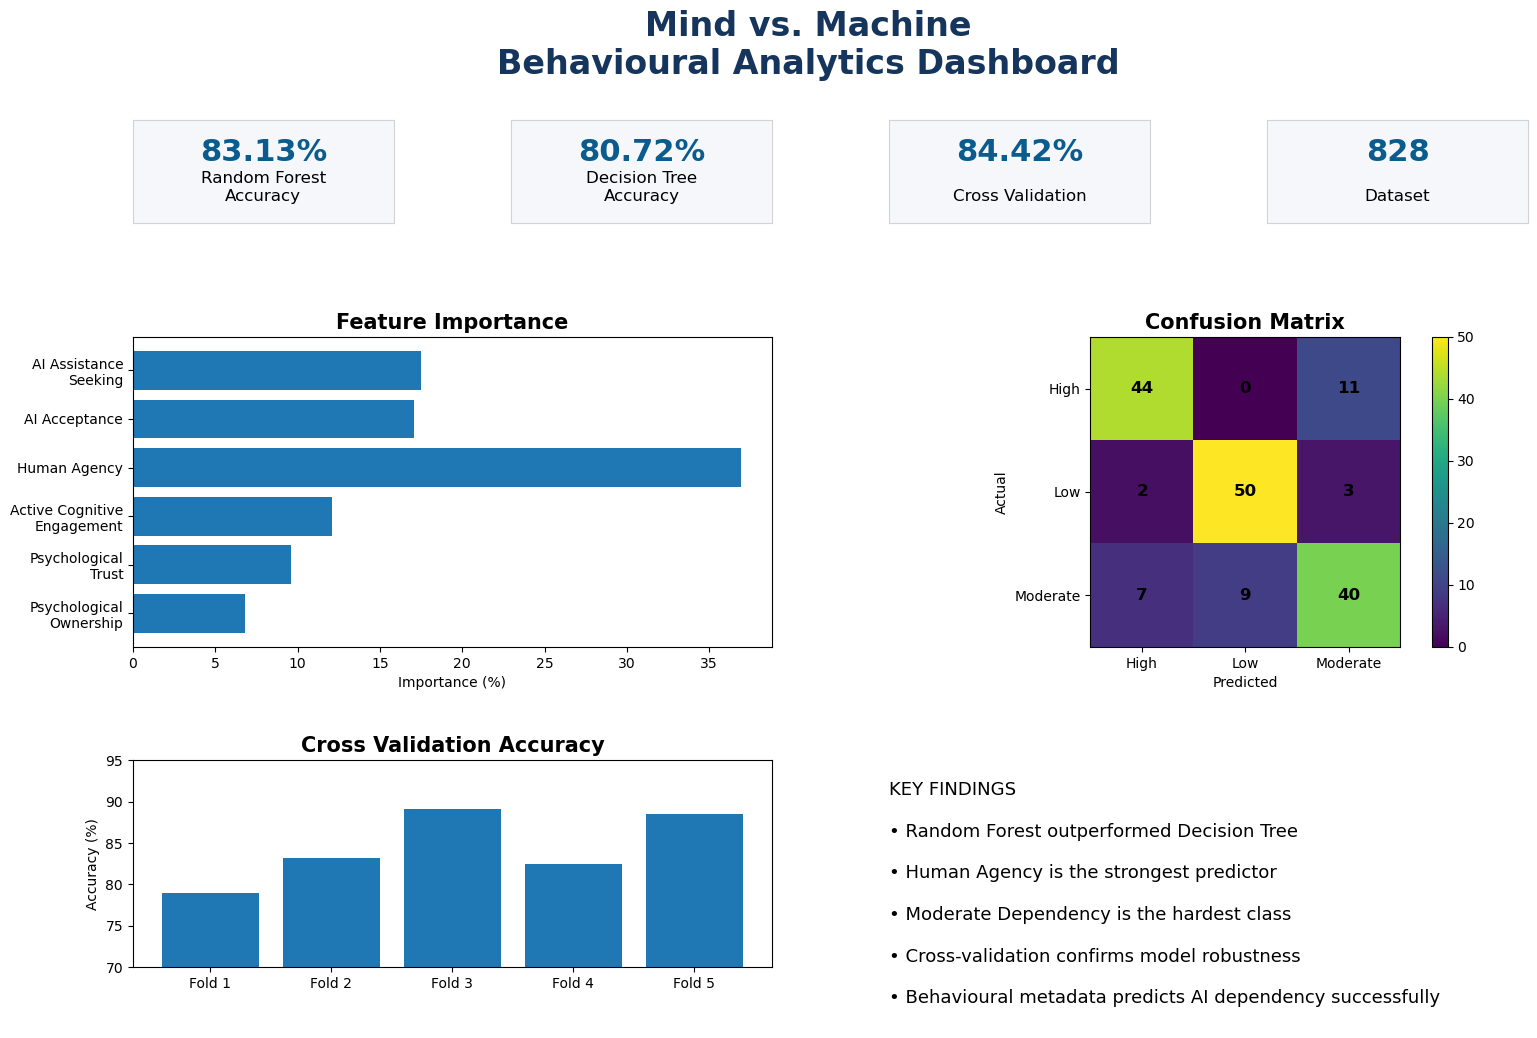

In [81]:
# ============================================================
# MIND VS. MACHINE
# Behavioural Analytics Dashboard
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ------------------------------------------------------------
# MODEL RESULTS
# ------------------------------------------------------------

rf_accuracy = 83.13
dt_accuracy = 80.72
cv_accuracy = 84.42
dataset_size = 828

feature_names = [
    "AI Assistance\nSeeking",
    "AI Acceptance",
    "Human Agency",
    "Active Cognitive\nEngagement",
    "Psychological\nTrust",
    "Psychological\nOwnership"
]

feature_importance = [
    17.52,
    17.07,
    36.95,
    12.06,
    9.60,
    6.80
]

# Cross Validation Scores
cv_scores = [78.92,83.13,89.16,82.42,88.48]

# Confusion Matrix
cm = np.array([
    [44,0,11],
    [2,50,3],
    [7,9,40]
])

# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------

fig = plt.figure(figsize=(18,11), facecolor="white")

gs = gridspec.GridSpec(
    3,
    4,
    height_ratios=[1,3,2],
    hspace=0.55,
    wspace=0.45
)

fig.suptitle(
    "Mind vs. Machine\nBehavioural Analytics Dashboard",
    fontsize=24,
    fontweight="bold",
    color="#16355C"
)

# ============================================================
# KPI CARDS
# ============================================================

cards = [
    ("Random Forest\nAccuracy","83.13%"),
    ("Decision Tree\nAccuracy","80.72%"),
    ("Cross Validation","84.42%"),
    ("Dataset","828")
]

for i,(title,value) in enumerate(cards):

    ax = fig.add_subplot(gs[0,i])

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_facecolor("#F5F7FA")

    for spine in ax.spines.values():
        spine.set_color("#D3D3D3")

    ax.text(
        0.5,
        0.60,
        value,
        fontsize=22,
        fontweight='bold',
        ha='center',
        color="#0B5C8E"
    )

    ax.text(
        0.5,
        0.22,
        title,
        fontsize=12,
        ha='center'
    )

# ============================================================
# FEATURE IMPORTANCE
# ============================================================

ax1 = fig.add_subplot(gs[1,:2])

y = np.arange(len(feature_names))

ax1.barh(
    y,
    feature_importance
)

ax1.set_yticks(y)
ax1.set_yticklabels(feature_names)

ax1.invert_yaxis()

ax1.set_xlabel("Importance (%)")

ax1.set_title(
    "Feature Importance",
    fontsize=15,
    fontweight='bold'
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

ax2 = fig.add_subplot(gs[1,2:])

img = ax2.imshow(cm)

ax2.set_title(
    "Confusion Matrix",
    fontsize=15,
    fontweight='bold'
)

labels = ["High","Low","Moderate"]

ax2.set_xticks(np.arange(3))
ax2.set_yticks(np.arange(3))

ax2.set_xticklabels(labels)
ax2.set_yticklabels(labels)

ax2.set_xlabel("Predicted")
ax2.set_ylabel("Actual")

for i in range(3):
    for j in range(3):
        ax2.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="black",
            fontsize=12,
            fontweight="bold"
        )

fig.colorbar(img, ax=ax2)

# ============================================================
# CROSS VALIDATION
# ============================================================

ax3 = fig.add_subplot(gs[2,:2])

folds = [
    "Fold 1",
    "Fold 2",
    "Fold 3",
    "Fold 4",
    "Fold 5"
]

ax3.bar(folds,cv_scores)

ax3.set_ylim(70,95)

ax3.set_ylabel("Accuracy (%)")

ax3.set_title(
    "Cross Validation Accuracy",
    fontsize=15,
    fontweight='bold'
)

# ============================================================
# KEY FINDINGS
# ============================================================

ax4 = fig.add_subplot(gs[2,2:])

ax4.axis("off")

findings = """
KEY FINDINGS

• Random Forest outperformed Decision Tree

• Human Agency is the strongest predictor

• Moderate Dependency is the hardest class

• Cross-validation confirms model robustness

• Behavioural metadata predicts AI dependency successfully
"""

ax4.text(
    0,
    1,
    findings,
    fontsize=13,
    va='top'
)

# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "AI_Dependency_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()